<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
from pathlib import Path


<h1> LEITURA DO DATASET BRUTO </H1>

In [2]:
dataset_path = "./dataset/radar-data-for-machine-fault-detection/dataset"
dataset_data_details = dataset_path + "/Data_Details.csv"

preprocessing_path = "./preprocessing/"
file_name = "02-raw_dataset.csv"

#funções auxiliares
def checarSeExiste(file):
    arquivo = Path(file)
    return arquivo.exists()

#funções de carregamento dos dados brutos
def load_dataDetails():
    df_details = pd.read_csv(dataset_data_details, sep=";") # lendo arquivo
    df_details = df_details.iloc[:, :-1] # removendo último coluna

    # Renomeando colunas
    df_details = df_details.rename(columns={
        "Data_name":"dataName",
        "Motor speed (rpm)":"motorSpeed",
        "Load (Nm)":"load",
        "Class":"class"
        })

    # Adicionando caminho dos dados brutos
    df_details["rawData"] = dataset_path + "/raw_data/" + \
        df_details["class"].str.lower().str.split(' ', n=1).str[0] + "/" + \
        df_details["dataName"] + ".csv"


    df_details['motorSpeed'] = pd.to_numeric(df_details["motorSpeed"].str.replace(",", ".", regex=False),  errors="coerce")
    df_details['load'] = pd.to_numeric(df_details["load"].str.replace(",", ".", regex=False),  errors="coerce")

    df_details = df_details.dropna(subset=["motorSpeed"])

    df_details["dataRawExists"] = df_details["rawData"].apply(checarSeExiste)
    df_details = df_details[df_details["dataRawExists"] == True]
    df_details = df_details.drop(columns="dataRawExists")
    df_details.reset_index(drop=True)

    return df_details


df_dataDetails = load_dataDetails()
df_dataDetails.to_csv(preprocessing_path + file_name, index=False)
df_dataDetails.info()



<class 'pandas.DataFrame'>
Index: 461 entries, 0 to 461
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dataName    461 non-null    str    
 1   motorSpeed  461 non-null    float64
 2   load        461 non-null    float64
 3   class       461 non-null    str    
 4   rawData     461 non-null    str    
dtypes: float64(2), str(3)
memory usage: 21.6 KB


In [3]:
import matplotlib.pyplot as plt

In [4]:
df_values = df_dataDetails['class']
print(df_values.value_counts())

class
Imbalance    198
Normal        66
Rotor         66
Bearing       66
Wound         65
Name: count, dtype: int64


Index(['Imbalance', 'Normal', 'Rotor', 'Bearing', 'Wound'], dtype='str', name='class')


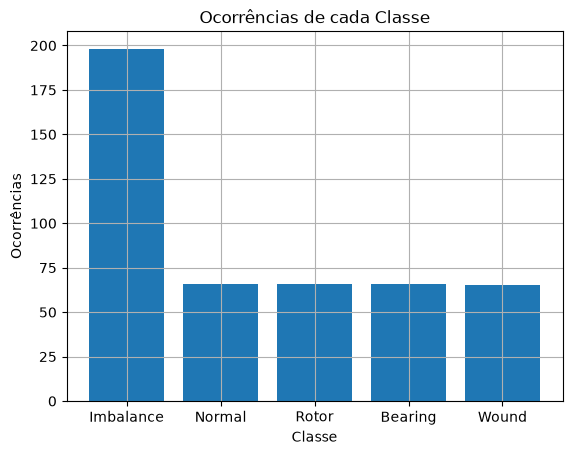

In [21]:
data = df_values.value_counts()
print(data.index)
plt.figure()
plt.bar(data.index, data.values)
plt.grid()
plt.xlabel("Classe")
plt.ylabel('Ocorrências')
plt.title("Ocorrências de cada Classe")
plt.show()

In [13]:
f = 50 #hz
ns = 120 * f/ 4 
s = (ns - 1452) / 1500

print(s)

0.032


In [45]:
def load_rawData(dataFile):
    df_rawData = pd.read_csv(dataFile, sep=",",decimal=".") # lendo arquivo

    df_rawData["module"] = np.sqrt(np.pow(df_rawData["Q_data"],2) + np.pow(df_rawData["I_data"],2)) # Calculando modulo do sinal
    df_rawData["fase"] = np.atan(df_rawData["Q_data"]/df_rawData["I_data"]) # Calculando fase do sinal

    df_rawData = df_rawData[df_rawData["module"] > 0] # Filtrando valores não nulos

    return df_rawData

def fig(rawData):
    fs = 10000  # Hz

    # Sinal complexo I + jQ
    sinal = (
        rawData["I_data"].values
        + 1j * rawData["Q_data"].values
    )

    N = len(sinal)

    # FFT
    fft = np.fft.fft(sinal)

    # Frequências
    frequencias = np.fft.fftfreq(N, 1 / fs)

    # Magnitude normalizada
    magnitude = np.abs(fft) / N

    # Frequências positivas
    mask = (frequencias >= 0) & (frequencias <= 200)

    frequencias = frequencias[mask]
    magnitude = magnitude[mask]

    # Magnitude em dB
    magnitude_db = 20 * np.log10(magnitude + 1e-12)

    return frequencias, magnitude_db



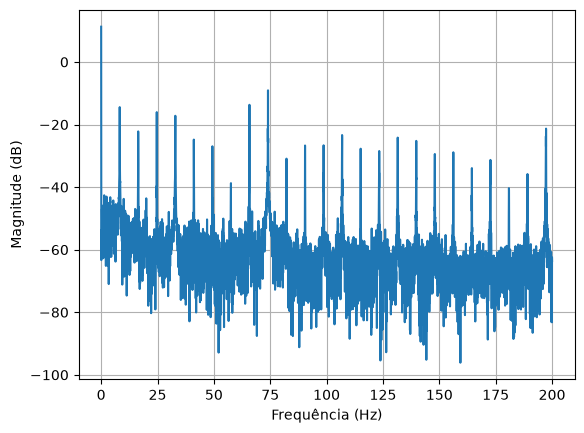

In [47]:
data =  df_dataDetails.loc[
        df_dataDetails['class'] == 'Rotor',
        'rawData'
    ].iloc[0]


a = fig(load_rawData(data))


plt.figure()

plt.plot(a[0], a[1])
plt.grid()
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude (dB)")
plt.show()


In [11]:
categorias = df_dataDetails['class'].unique

df_values = df_dataDetails['load']

modelos = []
for categoria in categorias:
    modelo = 
    modelos.append(modelo)

modelo_1 = [95, 82, 78, 90]
modelo_2 = [92, 88, 81, 85]
modelo_3 = [97, 85, 86, 93]

x = np.arange(len(categorias))
largura = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - largura, modelo_1, largura, label='Modelo 1')
plt.bar(x, modelo_2, largura, label='Modelo 2')
plt.bar(x + largura, modelo_3, largura, label='Modelo 3')

plt.xlabel('Classe')
plt.ylabel('Acurácia (%)')
plt.xticks(x, categorias, rotation=20)
plt.legend()

plt.tight_layout()
plt.show()

plt.show()

SyntaxError: invalid syntax (2613993466.py, line 7)